In [1]:
from langchain_groq import ChatGroq
import os
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
#create llm

llm=ChatGroq(
    model='openai/gpt-oss-120b'
)

In [3]:
#testing llm
llm.invoke("hello")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hello". We should respond appropriately, greeting back. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 72, 'total_tokens': 109, 'completion_time': 0.07917344, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.003093644, 'prompt_tokens_details': None, 'queue_time': 0.390989117, 'total_time': 0.082267084}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_9241e9962b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a18d86-441e-7d51-b3d7-40e6cec89642-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 37, 'total_tokens': 109, 'output_token_details': {'reasoning': 19}})

In [4]:
import sqlite3

conn = sqlite3.connect(r"E:\chatbot\booking\hospital.db")
cursor = conn.cursor()


def create_tables():

    cursor.execute("""
    CREATE TABLE doctors (
        doctor_id INTEGER PRIMARY KEY AUTOINCREMENT,
        name TEXT NOT NULL UNIQUE,
        morning_start TEXT,
        morning_end TEXT,
        break_start TEXT,
        break_end TEXT,
        evening_start TEXT,
        evening_end TEXT
    )
    """)

    doctors = [
        ("dr_sharma", "11:00", "13:00", "13:00", "14:00", "14:00", "20:00"),
        ("dr_khan", "10:00", "13:00", "13:00", "14:00", "14:00", "19:00")
    ]

    cursor.executemany("""
    INSERT INTO doctors (
        name, morning_start, morning_end,
        break_start, break_end, evening_start, evening_end
    )
    VALUES (?, ?, ?, ?, ?, ?, ?)
    """, doctors)


    cursor.execute("""
    CREATE TABLE IF NOT EXISTS appointments (
        appointment_id INTEGER PRIMARY KEY AUTOINCREMENT,
        patient_name TEXT NOT NULL,
        phone TEXT NOT NULL,
        doctor_name TEXT NOT NULL,
        appointment_date TEXT NOT NULL,
        session TEXT NOT NULL,
        queue_number INTEGER NOT NULL
    )
    """)

    conn.commit()

    print("Tables created successfully!")



In [5]:
create_tables()

Tables created successfully!


In [6]:
import re

def normalize_doctor_name(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())


def find_doctor(cursor, dr_name):

    user_name = normalize_doctor_name(dr_name)

    cursor.execute("SELECT * FROM doctors")
    doctors = cursor.fetchall()

    for doctor in doctors:

        db_name = normalize_doctor_name(doctor[1])

        if user_name == db_name:
            return doctor

    return None

In [7]:
from langchain_core.tools import tool
import sqlite3

@tool
def check_availability(dr_name: str, session: str):
    """Check a doctor's working hours for the morning or evening session."""

    conn = sqlite3.connect(r"E:\chatbot\booking\hospital.db")

    try:
        cursor = conn.cursor()

        doctor = find_doctor(cursor, dr_name)

        if doctor is None:
            return f"Sorry, {dr_name} was not found!"

        # Always use the original name stored in DB
        dr_name = doctor[1]

        morning_start = doctor[2]
        morning_end = doctor[3]
        evening_start = doctor[6]
        evening_end = doctor[7]

        session = session.lower().strip()

        if session == "morning":
            return (
                f"{dr_name} is available in the morning "
                f"from {morning_start} to {morning_end}."
            )

        elif session == "evening":
            return (
                f"{dr_name} is available in the evening "
                f"from {evening_start} to {evening_end}."
            )

        else:
            return "Please choose either morning or evening."

    finally:
        conn.close()

In [8]:

@tool
def book_appointment(
    patient_name: str,
    phone: str,
    dr_name: str,
    appointment_date: str,
    session: str
):
    """Book a hospital appointment after patient confirmation."""

    session = session.strip().lower()

    if session not in ("morning", "evening"):
        return "Please choose morning or evening."

    conn = sqlite3.connect(r"E:\chatbot\booking\hospital.db")

    try:
        cursor = conn.cursor()

        doctor = find_doctor(cursor, dr_name)

        if doctor is None:
            return f"Sorry, {dr_name} was not found!"

        # Use the standardized name from the doctors table
        dr_name = doctor[1]

        cursor.execute("""
            SELECT COALESCE(MAX(queue_number), 0) + 1
            FROM appointments
            WHERE doctor_name = ?
              AND appointment_date = ?
              AND session = ?
        """, (dr_name, appointment_date, session))

        queue_number = cursor.fetchone()[0]

        cursor.execute("""
            INSERT INTO appointments (
                patient_name, phone, doctor_name,
                appointment_date, session, queue_number
            )
            VALUES (?, ?, ?, ?, ?, ?)
        """, (
            patient_name.strip(),
            phone.strip(),
            dr_name,
            appointment_date,
            session,
            queue_number
        ))

        conn.commit()

        return (
            f"Appointment booked successfully! "
            f"Queue number: {queue_number}. "
            f"Doctor: {dr_name}. "
            f"Date: {appointment_date}. "
            f"Session: {session}. "
            "Your exact consultation time is not guaranteed."
        )

    except sqlite3.Error as e:
        conn.rollback()
        return f"Unable to book the appointment: {e}"

    finally:
        conn.close()


In [9]:

@tool
def find_appointments(phone: str) -> str:
    """Find existing appointments using the patient's phone number."""

    conn = sqlite3.connect(r"E:\chatbot\booking\hospital.db")

    try:
        cursor = conn.cursor()

        cursor.execute("""
            SELECT appointment_id, patient_name, doctor_name,
                   appointment_date, session, queue_number
            FROM appointments
            WHERE phone = ?
            ORDER BY appointment_date
        """, (phone.strip(),))

        appointments = cursor.fetchall()

        if not appointments:
            return "No appointments found for this phone number."

        result = []

        for appointment in appointments:
            result.append(
                f"Appointment ID: {appointment[0]}, "
                f"Patient: {appointment[1]}, "
                f"Doctor: {appointment[2]}, "
                f"Date: {appointment[3]}, "
                f"Session: {appointment[4]}, "
                f"Queue number: {appointment[5]}"
            )

        return "\n".join(result)

    finally:
        conn.close()


In [10]:

@tool
def update_appointment(
    appointment_id: int,
    patient_name: str,
    phone: str,
    dr_name: str,
    appointment_date: str,
    session: str
) -> str:
    """Update an appointment after patient confirmation."""

    session = session.strip().lower()

    if session not in ("morning", "evening"):
        return "Please choose morning or evening."

    conn = sqlite3.connect(r"E:\chatbot\booking\hospital.db")

    try:
        cursor = conn.cursor()

        cursor.execute("""
            SELECT appointment_id
            FROM appointments
            WHERE appointment_id = ?
        """, (appointment_id,))

        if cursor.fetchone() is None:
            return f"No appointment found with ID {appointment_id}."

        doctor = find_doctor(cursor, dr_name)

        if doctor is None:
            return f"Sorry, {dr_name} was not found."

        # Always use the standardized database name
        dr_name = doctor[1]

        cursor.execute("""
            SELECT COALESCE(MAX(queue_number), 0) + 1
            FROM appointments
            WHERE doctor_name = ?
              AND appointment_date = ?
              AND session = ?
              AND appointment_id != ?
        """, (dr_name, appointment_date, session, appointment_id))

        queue_number = cursor.fetchone()[0]

        cursor.execute("""
            UPDATE appointments
            SET patient_name = ?,
                phone = ?,
                doctor_name = ?,
                appointment_date = ?,
                session = ?,
                queue_number = ?
            WHERE appointment_id = ?
        """, (
            patient_name.strip(),
            phone.strip(),
            dr_name,
            appointment_date,
            session,
            queue_number,
            appointment_id
        ))

        conn.commit()

        return (
            f"Appointment updated successfully! "
            f"Appointment ID: {appointment_id}. "
            f"Patient: {patient_name}. "
            f"Doctor: {dr_name}. "
            f"Date: {appointment_date}. "
            f"Session: {session}. "
            f"New queue number: {queue_number}. "
            "The exact consultation time is not guaranteed."
        )

    except sqlite3.Error as e:
        conn.rollback()
        return f"Unable to update the appointment: {e}"

    finally:
        conn.close()


In [11]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

agent=create_agent(
    model=llm,
    tools=[check_availability,book_appointment,find_appointments,update_appointment],
    
system_prompt = """
You are an AI hospital appointment booking assistant.

Your responsibilities and rules:

1. Greet the patient politely and understand their requirements.

2. For a new appointment, collect:
   - Patient's full name
   - Preferred department or doctor
   - Preferred appointment date
   - Preferred session (morning or evening)
   - Patient's phone number

3. Ask for missing information one question at a time.
   If any required information is missing, unclear, or incomplete,
   politely ask the patient until you have the required details.
   Never proceed with booking or updating while required information
   is missing.

4. Never assume, guess, or invent information.
   Use only information explicitly provided by the patient or
   returned by available tools and the database.
   Never invent doctor names, departments, schedules, dates,
   phone numbers, appointment details, IDs, or queue numbers.

5. If information is ambiguous or conflicting, ask the patient
   to clarify it. Never choose an answer on the patient's behalf.

6. Use the available tools to check doctor availability and
   retrieve existing appointment details when needed.
   Never claim something is available unless the available
   information or tool supports it.

7. NEW APPOINTMENT BOOKING:
   Before booking, summarize:
   - Patient's name
   - Phone number
   - Doctor or department
   - Appointment date
   - Preferred session

   Ask for explicit confirmation before calling the
   book_appointment tool. Never book before confirmation.

8. APPOINTMENT UPDATING:
   If the patient wants to update an existing appointment:
   a. Ask for the phone number used for the booking if it
      has not already been provided.
   b. Use find_appointments to find their existing appointments.
   c. If no appointment is found, explain this honestly.
   d. If multiple appointments are found, show the available
      appointment details and ask which one they want to update.
   e. Never invent an appointment ID or assume which appointment
      the patient means.
   f. Ask what they want to change, such as their name, phone
      number, doctor, date, or session.
   g. Keep the existing information unchanged unless the patient
      requests a change.
   h. Ask for any missing or unclear information one question
      at a time.
   i. Check the requested details using the available tools.
   j. Summarize the existing appointment and all proposed changes.
   k. Ask the patient for explicit confirmation before calling
      update_appointment.
   l. If the patient does not confirm, do not update the appointment.
   m. Never create a new appointment when the patient only wants
      to update an existing one.

9. Do not call book_appointment or update_appointment until
   the patient has explicitly confirmed the relevant details.
   If the patient changes any details after confirmation,
   summarize the revised details and ask for confirmation again.

10. Never claim an appointment was booked or updated unless
    the corresponding tool successfully completes the operation.

11. After successful booking or updating, report the actual
    details returned by the tool, including the appointment ID
    and queue number when provided.
    Never invent a queue number or guarantee an exact consultation
    time. If the queue number changes, report the new number
    returned by the tool.

12. If a tool fails, information is unavailable, or a request
    cannot be completed, explain the situation honestly.
    Never pretend an operation succeeded.

13. Communicate in simple, polite, understandable English.
    Be patient and helpful. Ask only for missing or unclear
    information. Do not repeatedly ask for details already provided.

14. Keep the conversation focused on the patient's request.
    Do not make medical diagnoses or provide unsupported medical
    advice.

15. Never reveal private information about another patient.
    Only display appointment details relevant to the patient's
    own booking, and do not assume that knowing a phone number
    alone proves identity.
""",
    checkpointer=InMemorySaver()
)

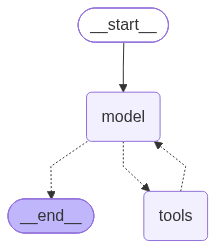

In [12]:
agent

In [13]:
config1={'configurable':{'thread_id':'chat1'}}
response=agent.invoke({'messages':'hello'},config=config1)

In [14]:
response['messages'][-1].content

'Hello! Welcome to our hospital appointment service. How may I assist you today? Are you looking to book a new appointment or update an existing one?'

In [15]:
while True:
    config4={'configurable':{'thread_id':'chat4'}}
    user_input=input('YOU: ')
    print('YOU: ',user_input)

    if user_input.lower().strip()=='exit':
        break

    response=agent.invoke({'messages':user_input},config=config4)

    print("BOT: ",response['messages'][-1].content)



YOU:  Hi, I’m Priya Desai. My phone number is 9123456780. I’d like to book an appointment with Dr. Khan on 31 october 2026 for the evening session. Please book it for me.
BOT:  Sure, Priya. Here’s a summary of the appointment you’d like to book:

- **Patient name:** Priya Desai  
- **Phone number:** 9123456780  
- **Doctor:** Dr. Khan  
- **Date:** 31 October 2026  
- **Session:** Evening (14:00 – 19:00)

Do you confirm that all of these details are correct and would like me to proceed with booking the appointment?
YOU:  yes confirmed
BOT:  Your appointment has been booked successfully!

- **Appointment ID:** (not provided)  
- **Queue number:** 1  
- **Doctor:** Dr. Khan  
- **Date:** 31 October 2026  
- **Session:** Evening  

Thank you, Priya! If you need to make any changes or have any other requests, just let me know.
YOU:  Hi, I’m Rahul Patil. My phone number is 9876543210. I’d like to book an appointment with Dr.khan on 31 october 2026 for the evening session. Could you please b